In [84]:
# ===========================================
# Import Required Libraries
# ===========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

# Plot style
plt.style.use('ggplot')

print("Libraries imported successfully.")

Libraries imported successfully.


In [85]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [86]:
# ===========================================
# Load Dataset
# ===========================================

file_path = "/content/drive/MyDrive/My Thesis/air_quality_Updated.xlsx"

air = pd.read_excel(file_path)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [87]:
air.head()

,date,PM10,PM2.5,RH,Temp,WD,WS
0,2024-01-01 00:00:00,223.814714,65.119368,NaN,28.618305,260.566102,0.604881
1,2024-01-01 01:00:00,343.645577,108.224682,NaN,28.438167,279.908333,1.534783
2,2024-01-01 02:00:00,445.856723,140.734862,NaN,27.912167,285.158333,1.327000
3,2024-01-01 03:00:00,407.405071,138.152391,NaN,27.583500,289.420000,1.447833
4,2024-01-01 04:00:00,400.491289,126.808911,NaN,27.357000,286.768333,1.326083


In [88]:
air.tail()

,date,PM10,PM2.5,RH,Temp,WD,WS
17539,2025-12-31 19:00:00,183.883245,64.617278,85.148333,28.364167,62.926255,1.489117
17540,2025-12-31 20:00:00,204.157628,68.951624,84.783333,27.799333,41.555254,1.145500
17541,2025-12-31 21:00:00,218.353663,72.403154,89.611667,27.263000,72.567298,0.888067
17542,2025-12-31 22:00:00,206.827098,64.702803,94.235000,27.243167,50.476667,1.318717
17543,2025-12-31 23:00:00,191.546738,56.513579,98.625000,26.738833,52.789293,1.254533


In [89]:
# Dataset dimensions

rows, columns = air.shape

print(f"Number of observations : {rows}")
print(f"Number of variables    : {columns}")

print("=================================")
# Display variable names

air.columns.tolist()

Number of observations : 17544
Number of variables    : 7


['date', 'PM10', 'PM2.5', 'RH', 'Temp', 'WD', 'WS']

In [90]:
# Data types

air.dtypes
#print("===========================\n")
# Dataset information

air.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    17544 non-null  datetime64[ns]
 1   PM10    17007 non-null  float64       
 2   PM2.5   16988 non-null  float64       
 3   RH      8327 non-null   float64       
 4   Temp    17438 non-null  float64       
 5   WD      17385 non-null  float64       
 6   WS      15263 non-null  float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 959.6 KB


In [91]:
# Dataset Overvier table
overview = pd.DataFrame({
    "Variable": air.columns,
    "Data Type": air.dtypes.values,
    "Missing Values": air.isna().sum().values,
    "Missing (%)": round((air.isna().sum()/len(air))*100,2).values
})

overview

,Variable,Data Type,Missing Values,Missing (%)
0,date,datetime64[ns],0,0.00
1,PM10,float64,537,3.06
2,PM2.5,float64,556,3.17
3,RH,float64,9217,52.54
4,Temp,float64,106,0.60
5,WD,float64,159,0.91
6,WS,float64,2281,13.00


In [92]:
# ==========================================
# Monitoring Period
# ==========================================

start_date = air['date'].min()
end_date = air['date'].max()

print(f"Start Date : {start_date}")
print(f"End Date   : {end_date}")

duration = end_date - start_date

print(f"\nMonitoring Duration : {duration}")

Start Date : 2024-01-01 00:00:00
End Date   : 2025-12-31 23:00:00

Monitoring Duration : 730 days 23:00:00


In [93]:
# ==========================================
# Expected Hourly Records
# ==========================================

expected_hours = pd.date_range(
    start=start_date,
    end=end_date,
    freq='H'
)

print(f"Expected hourly observations : {len(expected_hours)}")
print(f"Actual observations          : {len(air)}")

Expected hourly observations : 17544
Actual observations          : 17544


/tmp/ipykernel_725/1380670190.py:5: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  expected_hours = pd.date_range(


In [94]:
# ==========================================
# Missing Timestamps
# ==========================================

missing_times = expected_hours.difference(air['date'])

print(f"Missing timestamps : {len(missing_times)}")


print(" ==========================================")

# Duplicate Timestamps

duplicates = air['date'].duplicated().sum()

print(f"Duplicate timestamps : {duplicates}")
print(" ==========================================")

# Sampling Interval

time_difference = air['date'].diff()

time_difference.value_counts().head()

Missing timestamps : 0
Duplicate timestamps : 0


,count
date,
0 days 01:00:00,17543


In [95]:
# ==========================================
# Temporal Summary
# ==========================================

temporal_summary = pd.DataFrame({
    "Metric": [
        "Start Date",
        "End Date",
        "Total Records",
        "Expected Records",
        "Missing Timestamps",
        "Duplicate Timestamps"
    ],
    "Value": [
        start_date,
        end_date,
        len(air),
        len(expected_hours),
        len(missing_times),
        duplicates
    ]
})

temporal_summary

,Metric,Value
0,Start Date,2024-01-01 00:00:00
1,End Date,2025-12-31 23:00:00
2,Total Records,17544
3,Expected Records,17544
4,Missing Timestamps,0
5,Duplicate Timestamps,0


In [96]:
# ==========================================
# Missing Value Summary
# ==========================================

missing_summary = (
    air.isnull()
       .sum()
       .to_frame(name="Missing Values")
)

missing_summary["Percentage (%)"] = (
    missing_summary["Missing Values"] /
    len(air) * 100
).round(2)

missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

missing_summary

,Missing Values,Percentage (%)
RH,9217,52.54
WS,2281,13.00
PM2.5,556,3.17
PM10,537,3.06
WD,159,0.91
Temp,106,0.60
date,0,0.00


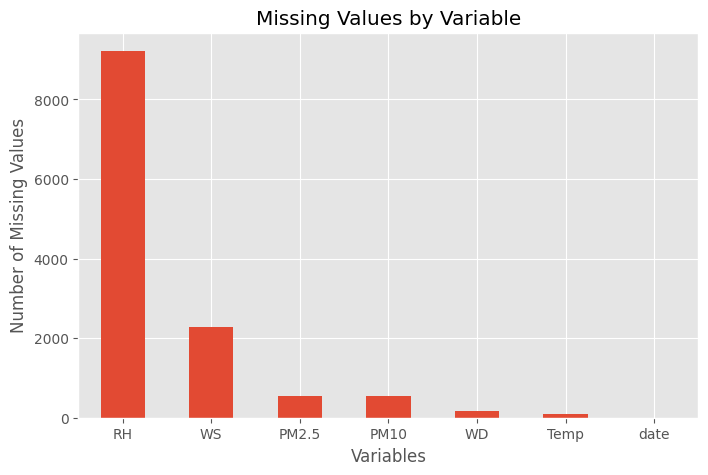

In [97]:
# ==========================================
# Missing Values Bar Chart
# ==========================================

missing_summary.plot(
    kind="bar",
    y="Missing Values",
    figsize=(8,5),
    legend=False
)

plt.title("Missing Values by Variable")
plt.ylabel("Number of Missing Values")
plt.xlabel("Variables")

plt.xticks(rotation=0)

plt.show()

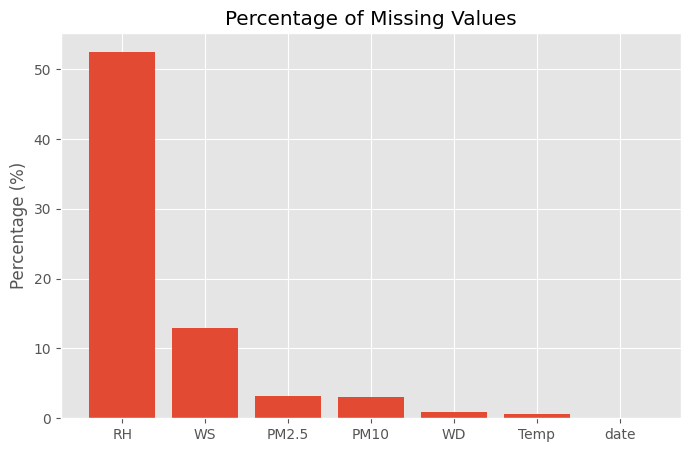

In [98]:
plt.figure(figsize=(8,5))

plt.bar(
    missing_summary.index,
    missing_summary["Percentage (%)"]
)

plt.ylabel("Percentage (%)")
plt.title("Percentage of Missing Values")

plt.show()

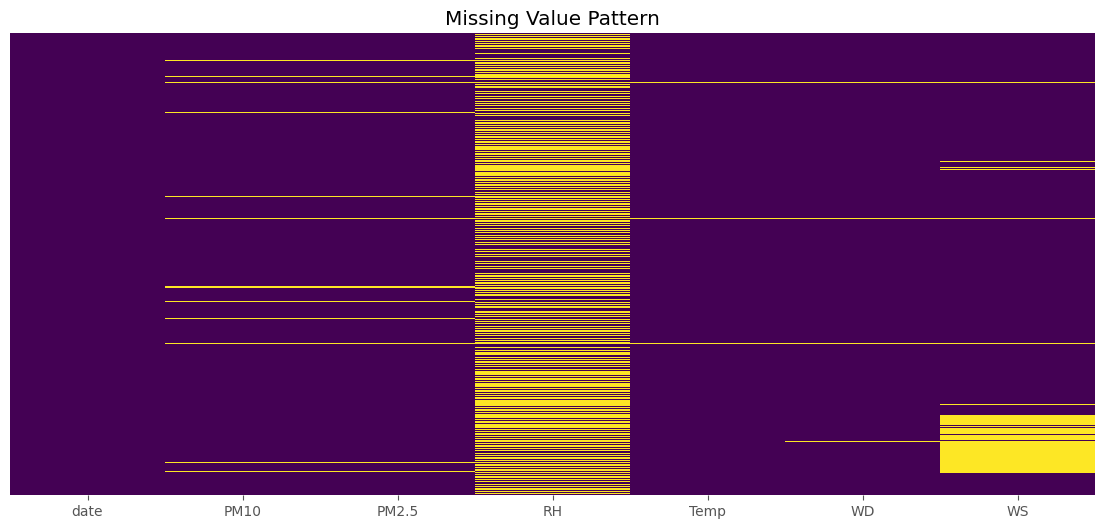

In [99]:
plt.figure(figsize=(14,6))

sns.heatmap(
    air.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Value Pattern")

plt.show()

In [100]:
# ==========================================
# Missing Values Through Time
# ==========================================

missing_daily = (
    air
    .set_index("date")
    .isnull()
    .resample("D")
    .sum()
)

missing_daily.head()

,PM10,PM2.5,RH,Temp,WD,WS
date,,,,,,
2024-01-01,0,0,12,0,0,0
2024-01-02,0,0,14,0,0,0
2024-01-03,0,0,12,0,0,0
2024-01-04,0,0,8,0,0,0
2024-01-05,0,0,12,0,0,0


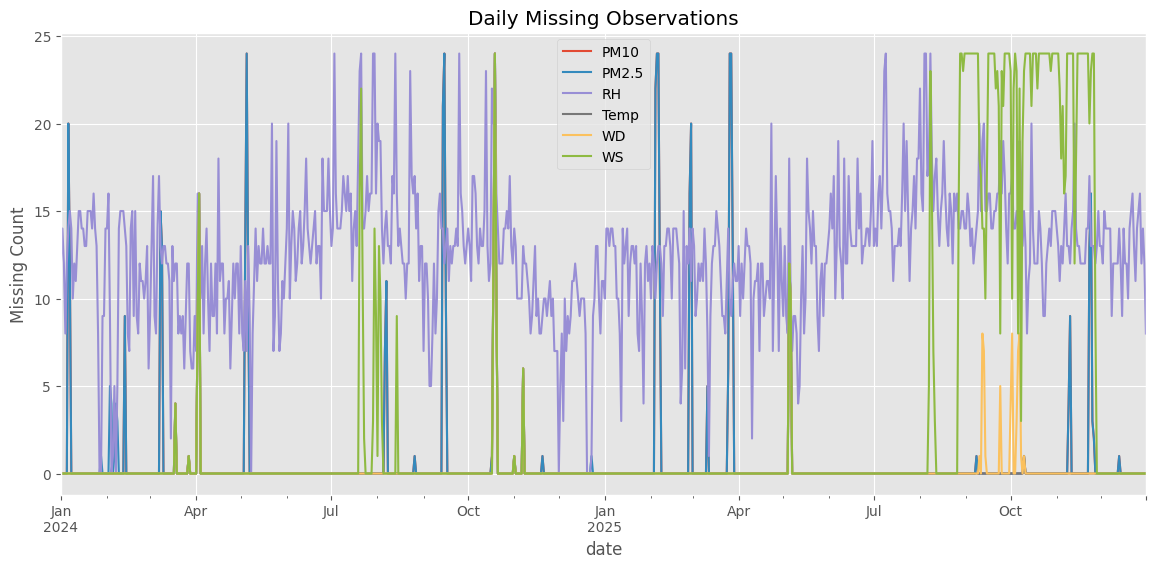

In [101]:
missing_daily.plot(
    figsize=(14,6)
)

plt.title("Daily Missing Observations")

plt.ylabel("Missing Count")

plt.show()

In [102]:
# ==========================================
# Missing Value Correlation
# ==========================================

missing_pattern = air.isnull().astype(int)

missing_pattern.corr()

,date,PM10,PM2.5,RH,Temp,WD,WS
date,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PM10,NaN,1.000000,0.982216,0.033053,0.438764,0.353131,0.079873
PM2.5,NaN,0.982216,1.000000,0.025997,0.430961,0.346647,0.076151
RH,NaN,0.033053,0.025997,1.000000,0.074106,0.086081,0.080655
Temp,NaN,0.438764,0.430961,0.074106,1.000000,0.815255,0.201680
WD,NaN,0.353131,0.346647,0.086081,0.815255,1.000000,0.238440
WS,NaN,0.079873,0.076151,0.080655,0.201680,0.238440,1.000000


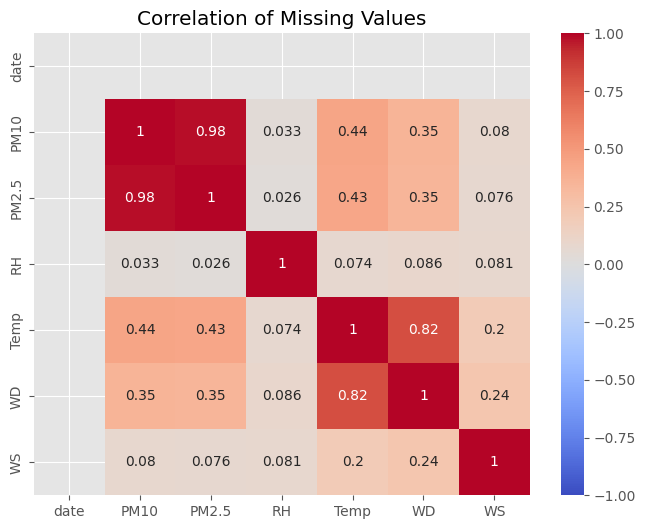

In [103]:
plt.figure(figsize=(8,6))

sns.heatmap(
    missing_pattern.corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation of Missing Values")

plt.show()

In [104]:
# ==========================================
# Consecutive Missing Values
# ==========================================

for column in air.columns[1:]:

    mask = air[column].isna()

    groups = (
        mask.ne(mask.shift())
        .cumsum()
    )

    runs = (
        mask.groupby(groups)
        .sum()
    )

    print(f"\n{column}")
    print(runs[runs > 0].describe())


PM10
count    30.000000
mean     17.900000
std      22.342707
min       1.000000
25%       1.000000
50%       4.500000
75%      28.750000
max      81.000000
Name: PM10, dtype: float64

PM2.5
count    37.000000
mean     15.027027
std      20.975497
min       1.000000
25%       1.000000
50%       4.000000
75%      23.000000
max      81.000000
Name: PM2.5, dtype: float64

RH
count    806.000000
mean      11.435484
std        6.050116
min        1.000000
25%        8.000000
50%       12.000000
75%       14.000000
max       65.000000
Name: RH, dtype: float64

Temp
count    10.000000
mean     10.600000
std      15.086418
min       1.000000
25%       1.250000
50%       3.000000
75%      17.500000
max      46.000000
Name: Temp, dtype: float64

WD
count    25.0000
mean      6.3600
std      10.1155
min       1.0000
25%       1.0000
50%       2.0000
75%       6.0000
max      46.0000
Name: WD, dtype: float64

WS
count     72.000000
mean      31.680556
std       55.374481
min        1.000000
25%  

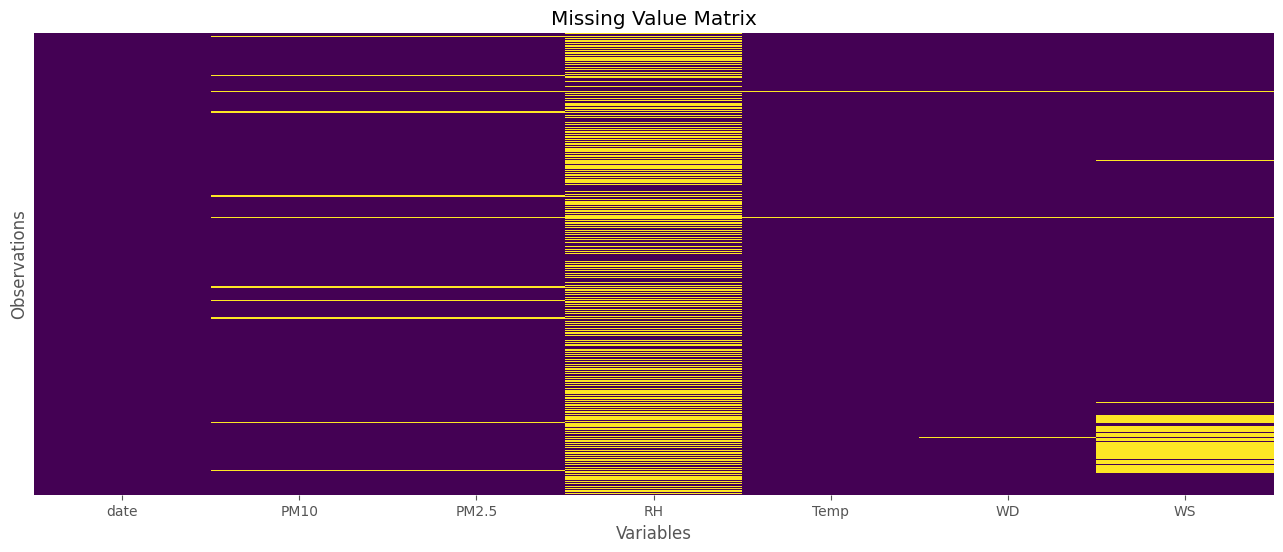

In [105]:
# ==========================================
# Missing Data Matrix
# ==========================================

plt.figure(figsize=(16,6))

sns.heatmap(
    air.isnull(),
    cmap="viridis",
    cbar=False,
    yticklabels=False
)

plt.title("Missing Value Matrix")
plt.xlabel("Variables")
plt.ylabel("Observations")

plt.show()


In [106]:
# ==========================================
# Daily Missing Values
# ==========================================

daily_missing = (
    air
    .set_index("date")
    .isnull()
    .resample("D")
    .sum()
)

daily_missing.head()

,PM10,PM2.5,RH,Temp,WD,WS
date,,,,,,
2024-01-01,0,0,12,0,0,0
2024-01-02,0,0,14,0,0,0
2024-01-03,0,0,12,0,0,0
2024-01-04,0,0,8,0,0,0
2024-01-05,0,0,12,0,0,0


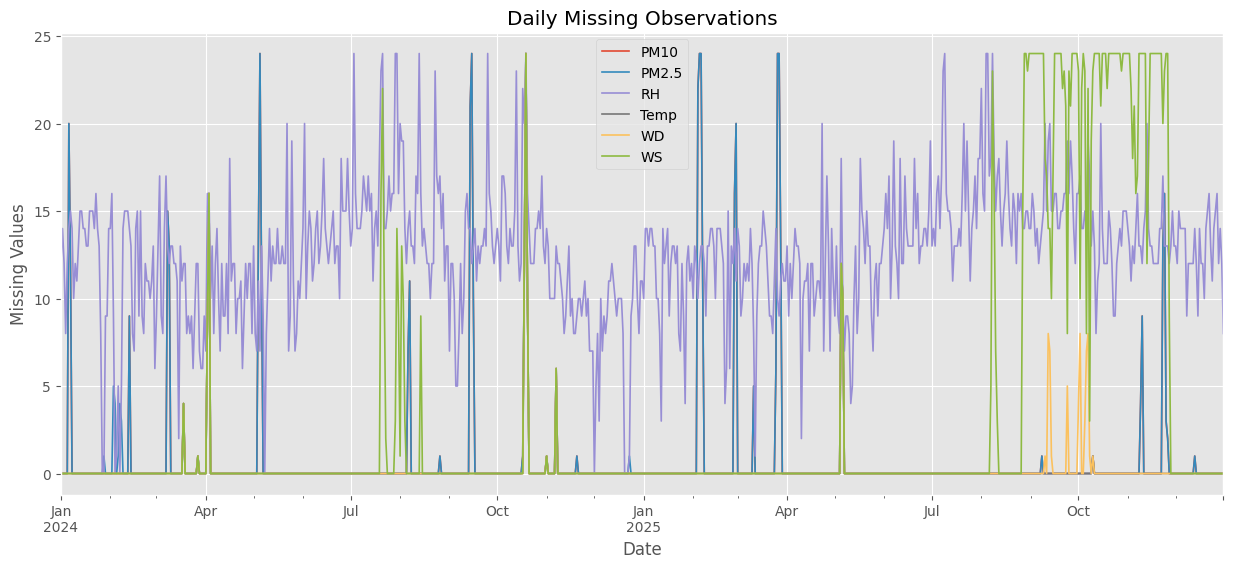

In [107]:
daily_missing.plot(
    figsize=(15,6),
    linewidth=1.2
)

plt.title("Daily Missing Observations")
plt.xlabel("Date")
plt.ylabel("Missing Values")

plt.show()

In [108]:
# ==========================================
# Monthly Missing Values
# ==========================================

monthly_missing = (
    air
    .set_index("date")
    .isnull()
    .resample("M")
    .sum()
)

monthly_missing

/tmp/ipykernel_725/4170819825.py:9: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .resample("M")


,PM10,PM2.5,RH,Temp,WD,WS
date,,,,,,
2024-01-31,32,33,373,0,0,0
2024-02-29,9,26,295,0,0,0
2024-03-31,33,33,324,5,5,5
2024-04-30,25,25,324,25,25,25
2024-05-31,48,48,338,0,0,0
2024-06-30,0,0,421,0,0,0
2024-07-31,0,0,509,0,0,77
2024-08-31,19,19,462,0,0,36
2024-09-30,55,55,369,0,0,0


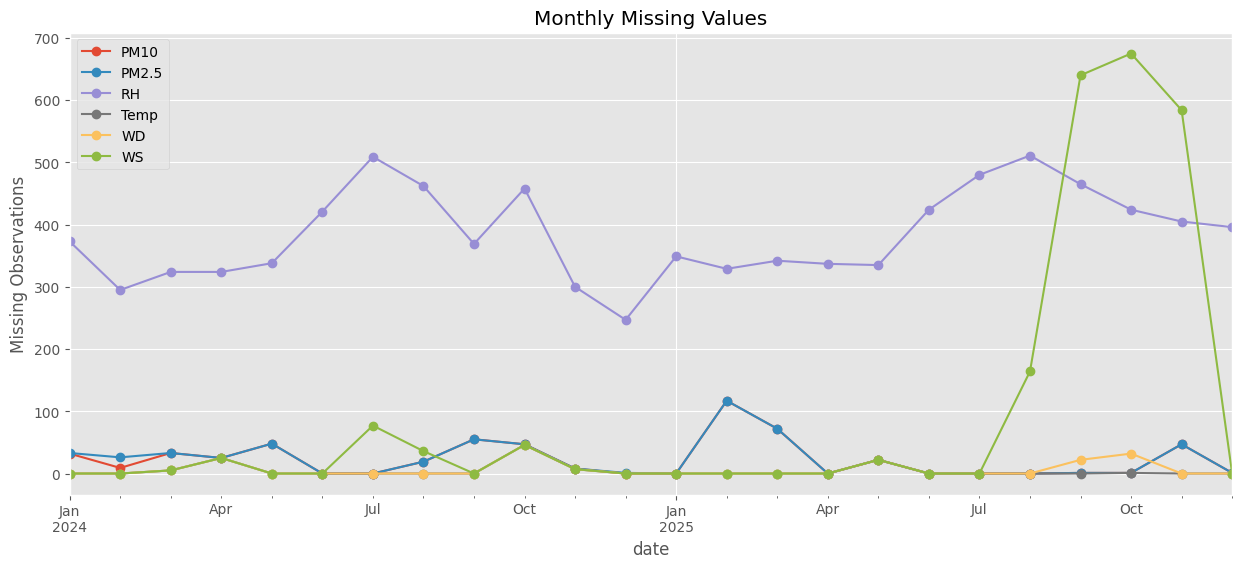

In [109]:
monthly_missing.plot(
    figsize=(15,6),
    marker='o'
)

plt.title("Monthly Missing Values")
plt.ylabel("Missing Observations")

plt.show()

In [110]:
# ==========================================
# Missing Value Correlation
# ==========================================

missing_corr = (
    air
    .isnull()
    .astype(int)
    .corr()
)

missing_corr

,date,PM10,PM2.5,RH,Temp,WD,WS
date,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PM10,NaN,1.000000,0.982216,0.033053,0.438764,0.353131,0.079873
PM2.5,NaN,0.982216,1.000000,0.025997,0.430961,0.346647,0.076151
RH,NaN,0.033053,0.025997,1.000000,0.074106,0.086081,0.080655
Temp,NaN,0.438764,0.430961,0.074106,1.000000,0.815255,0.201680
WD,NaN,0.353131,0.346647,0.086081,0.815255,1.000000,0.238440
WS,NaN,0.079873,0.076151,0.080655,0.201680,0.238440,1.000000


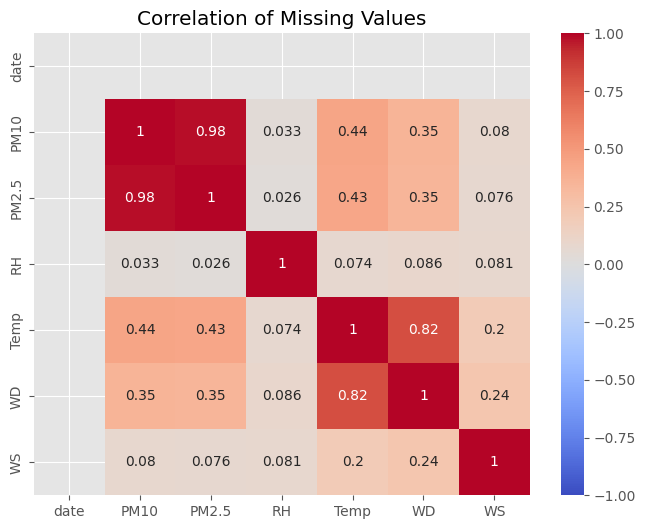

In [111]:
plt.figure(figsize=(8,6))

sns.heatmap(
    missing_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation of Missing Values")

plt.show()

In [112]:
# ==========================================
# Missing Value Timeline
# ==========================================

missing_dates = air.loc[
    air.isnull().any(axis=1),
    ['date']
]

print(f"Rows containing missing values: {len(missing_dates)}")

missing_dates.head()

Rows containing missing values: 10272


,date
0,2024-01-01 00:00:00
1,2024-01-01 01:00:00
2,2024-01-01 02:00:00
3,2024-01-01 03:00:00
4,2024-01-01 04:00:00


In [113]:
# ==========================================
# Missing Value Timeline
# ==========================================

missing_dates = air.loc[
    air.isnull().any(axis=1),
    ['date']
]

print(f"Rows containing missing values: {len(missing_dates)}")

missing_dates.head()

Rows containing missing values: 10272


,date
0,2024-01-01 00:00:00
1,2024-01-01 01:00:00
2,2024-01-01 02:00:00
3,2024-01-01 03:00:00
4,2024-01-01 04:00:00


In [114]:
# ==========================================
# Descriptive Statistics
# ==========================================

air.describe().T

,count,mean,min,25%,50%,75%,max,std
date,17544,2024-12-31 11:30:00,2024-01-01 00:00:00,2024-07-01 17:45:00,2024-12-31 11:30:00,2025-07-02 05:15:00,2025-12-31 23:00:00,NaN
PM10,17007.0,76.146507,4.638015,29.629185,41.84376,75.273115,1496.48715,121.569409
PM2.5,16988.0,24.508325,1.540185,12.254507,17.220897,26.773879,249.6048,26.4981
RH,8327.0,85.09312,25.8505,76.711917,87.183333,95.620465,99.9,12.13958
Temp,17438.0,28.160152,22.265167,26.056125,27.810083,29.866042,36.717241,2.781005
WD,17385.0,222.805585,5.736,191.841667,227.01,266.543333,354.8,57.046027
WS,15263.0,0.916022,0.001,0.248942,0.393483,1.478175,19.85,1.136848


In [115]:
# ==========================================
# Minimum and Maximum Values
# ==========================================

range_check = pd.DataFrame({
    "Minimum": air.min(numeric_only=True),
    "Maximum": air.max(numeric_only=True)
})

range_check

,Minimum,Maximum
PM10,4.638015,1496.487150
PM2.5,1.540185,249.604800
RH,25.850500,99.900000
Temp,22.265167,36.717241
WD,5.736000,354.800000
WS,0.001000,19.850000


In [116]:
# ==========================================
# Negative Value Check
# ==========================================

numeric_cols = ['PM10', 'PM2.5', 'RH', 'Temp', 'WD', 'WS']

negative_values = {}

for col in numeric_cols:
    negative_values[col] = (air[col] < 0).sum()

pd.DataFrame.from_dict(
    negative_values,
    orient='index',
    columns=['Negative Values']
)

,Negative Values
PM10,0
PM2.5,0
RH,0
Temp,0
WD,0
WS,0


In [117]:
# ==========================================
# Relative Humidity Validation
# ==========================================

invalid_rh = air[
    (air['RH'] < 0) |
    (air['RH'] > 100)
]

print("Invalid RH observations:", len(invalid_rh))

Invalid RH observations: 0


In [118]:
# ==========================================
# Wind Direction Validation
# ==========================================

invalid_wd = air[
    (air['WD'] < 0) |
    (air['WD'] > 360)
]

print("Invalid Wind Direction:", len(invalid_wd))

Invalid Wind Direction: 0


In [119]:
# ==========================================
# Wind Speed Validation
# ==========================================

invalid_ws = air[
    air['WS'] < 0
]

print("Negative Wind Speed:", len(invalid_ws))

Negative Wind Speed: 0


In [120]:
# ==========================================
# Temperature Validation
# ==========================================

invalid_temp = air[
    (air['Temp'] < 10) |
    (air['Temp'] > 45)
]

print("Potential Temperature Outliers:", len(invalid_temp))

Potential Temperature Outliers: 0


In [121]:
# ==========================================
# Validation Summary
# ==========================================

validation_summary = pd.DataFrame({
    "Check": [
        "Negative PM10",
        "Negative PM2.5",
        "Invalid RH",
        "Invalid Temperature",
        "Invalid Wind Direction",
        "Negative Wind Speed"
    ],
    "Count": [
        (air['PM10'] < 0).sum(),
        (air['PM2.5'] < 0).sum(),
        len(invalid_rh),
        len(invalid_temp),
        len(invalid_wd),
        len(invalid_ws)
    ]
})

validation_summary

,Check,Count
0,Negative PM10,0
1,Negative PM2.5,0
2,Invalid RH,0
3,Invalid Temperature,0
4,Invalid Wind Direction,0
5,Negative Wind Speed,0


In [122]:
air['RH'].describe()

#print("\n ========================")

#air['RH'].max()

,RH
count,8327.000000
mean,85.093120
std,12.139580
min,25.850500
25%,76.711917
50%,87.183333
75%,95.620465
max,99.900000


In [123]:
air['RH'].max()

99.90000000000002

In [124]:
air["WS"].describe()

,WS
count,15263.000000
mean,0.916022
std,1.136848
min,0.001000
25%,0.248942
50%,0.393483
75%,1.478175
max,19.850000


In [125]:
air["WS"].value_counts().sort_index().head(20)

,count
WS,
0.001000,2
0.003000,1
0.005000,1
0.005800,1
0.006000,1
0.006875,1
0.007250,1
0.008000,1
0.009000,1


In [126]:
air.nsmallest(20, "WS")[["date", "WS", "WD", "Temp", "RH"]]

,date,WS,WD,Temp,RH
14027,2025-08-07 11:00:00,0.001000,54.602414,25.939333,99.138095
14087,2025-08-09 23:00:00,0.001000,70.421833,23.741333,NaN
14030,2025-08-07 14:00:00,0.003000,59.675683,26.004833,99.128571
14095,2025-08-10 07:00:00,0.005000,86.562712,24.132500,NaN
14094,2025-08-10 06:00:00,0.005800,99.338000,23.556500,NaN
14092,2025-08-10 04:00:00,0.006000,83.899333,23.473333,NaN
4857,2024-07-21 09:00:00,0.006875,203.456224,25.343667,NaN
14088,2025-08-10 00:00:00,0.007250,85.807458,23.585000,NaN
14037,2025-08-07 21:00:00,0.008000,86.831772,24.346000,NaN
15235,2025-09-26 19:00:00,0.009000,173.956667,26.024333,NaN


In [127]:
air.nlargest(20, "WS")[["date", "WS", "WD", "Temp", "RH"]]

,date,WS,WD,Temp,RH
14934,2025-09-14 06:00:00,19.850000,30.313500,23.490167,NaN
16203,2025-11-06 03:00:00,19.795385,185.515000,23.953000,NaN
14881,2025-09-12 01:00:00,19.365833,353.141667,25.300500,NaN
14887,2025-09-12 07:00:00,18.575000,352.655000,25.419333,NaN
16154,2025-11-04 02:00:00,18.503333,133.515000,24.206333,NaN
14880,2025-09-12 00:00:00,18.402500,353.468333,25.367167,NaN
16381,2025-11-13 13:00:00,18.096667,188.650000,24.053000,NaN
15505,2025-10-08 01:00:00,17.877333,85.656500,22.980167,NaN
16206,2025-11-06 06:00:00,17.448947,241.990000,24.486500,NaN
14879,2025-09-11 23:00:00,16.638750,353.745000,25.398500,NaN


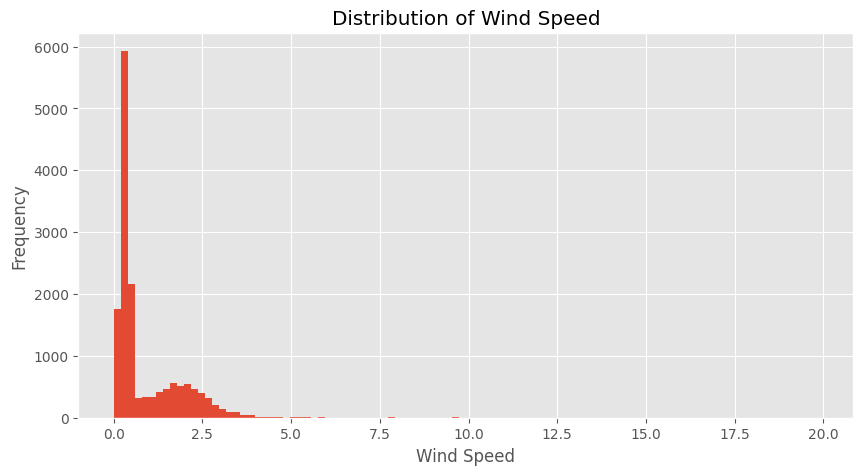

In [128]:
plt.figure(figsize=(10,5))

plt.hist(
    air["WS"],
    bins=100
)

plt.xlabel("Wind Speed")
plt.ylabel("Frequency")
plt.title("Distribution of Wind Speed")

plt.show()

In [129]:
# Wind speeds greater than 25 m/s
high_ws = air[air["WS"] > 25]

print("Number of observations:", len(high_ws))

high_ws[["date", "WS", "WD", "Temp", "RH"]].head(20)

Number of observations: 0


,date,WS,WD,Temp,RH


In [130]:
negative_ws = air[air["WS"] < 0]

print("Negative observations:", len(negative_ws))

negative_ws[["date", "WS", "WD", "Temp", "RH"]].head(20)

Negative observations: 0


,date,WS,WD,Temp,RH


In [131]:
# ==========================================
# Comprehensive Descriptive Statistics
# ==========================================

from scipy.stats import skew, kurtosis

numeric_cols = ['PM10', 'PM2.5', 'RH', 'Temp', 'WD', 'WS']

summary_stats = pd.DataFrame(index=numeric_cols)

summary_stats["Count"] = air[numeric_cols].count()
summary_stats["Missing"] = air[numeric_cols].isna().sum()
summary_stats["Mean"] = air[numeric_cols].mean()
summary_stats["Median"] = air[numeric_cols].median()
summary_stats["Std Dev"] = air[numeric_cols].std()
summary_stats["Minimum"] = air[numeric_cols].min()
summary_stats["25%"] = air[numeric_cols].quantile(0.25)
summary_stats["75%"] = air[numeric_cols].quantile(0.75)
summary_stats["Maximum"] = air[numeric_cols].max()
summary_stats["Range"] = (
    summary_stats["Maximum"] - summary_stats["Minimum"]
)

summary_stats["Skewness"] = air[numeric_cols].apply(
    lambda x: skew(x.dropna())
)

summary_stats["Kurtosis"] = air[numeric_cols].apply(
    lambda x: kurtosis(x.dropna())
)

summary_stats = summary_stats.round(2)

summary_stats

,Count,Missing,Mean,Median,Std Dev,Minimum,25%,75%,Maximum,Range,Skewness,Kurtosis
PM10,17007,537,76.15,41.84,121.57,4.64,29.63,75.27,1496.49,1491.85,5.70,39.43
PM2.5,16988,556,24.51,17.22,26.50,1.54,12.25,26.77,249.60,248.06,4.62,26.50
RH,8327,9217,85.09,87.18,12.14,25.85,76.71,95.62,99.90,74.05,-1.07,1.70
Temp,17438,106,28.16,27.81,2.78,22.27,26.06,29.87,36.72,14.45,0.48,-0.45
WD,17385,159,222.81,227.01,57.05,5.74,191.84,266.54,354.80,349.06,-1.05,1.57
WS,15263,2281,0.92,0.39,1.14,0.00,0.25,1.48,19.85,19.85,4.83,52.76


## Key Findings

- PM₂.₅ and PM₁₀ exhibit strong positive skewness, indicating occasional high-pollution episodes.
- PM₁₀ shows greater variability than PM₂.₅ and contains very large extreme observations that warrant further investigation.
- Temperature remains relatively stable and falls within expected climatological limits.
- Relative humidity is consistently high, reflecting the humid tropical conditions of the study area.
- Wind direction will require circular statistical methods for appropriate interpretation.
- The variable labelled `WS` displays anomalous statistical characteristics and remains under investigation pending metadata confirmation.

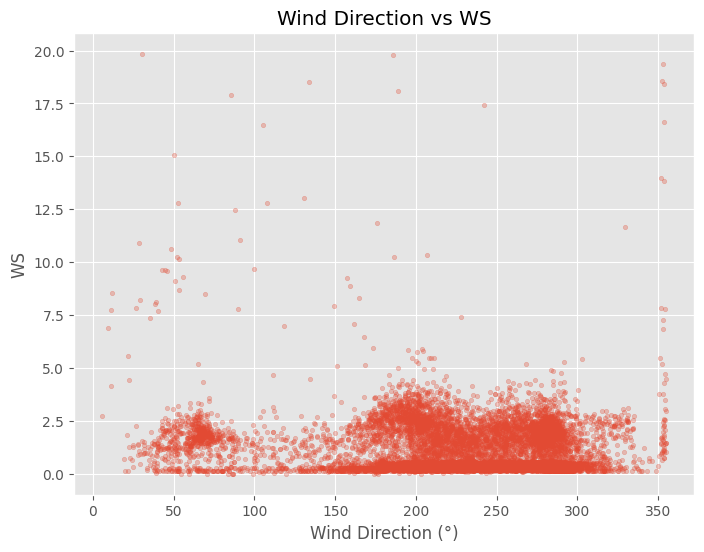

In [132]:
plt.figure(figsize=(8,6))

plt.scatter(
    air["WD"],
    air["WS"],
    alpha=0.3,
    s=10
)

plt.xlabel("Wind Direction (°)")
plt.ylabel("WS")
plt.title("Wind Direction vs WS")

plt.show()

In [133]:
# Divide wind direction into 8 compass sectors
bins = [0, 45, 90, 135, 180, 225, 270, 315, 360]
labels = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]

air["WD_sector"] = pd.cut(
    air["WD"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

air.groupby("WD_sector")["WS"].mean()

/tmp/ipykernel_725/782364127.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  air.groupby("WD_sector")["WS"].mean()


,WS
WD_sector,
N,2.184672
NE,1.734440
E,1.371075
SE,1.072237
S,0.952351
SW,0.682996
W,0.892495
NW,2.047113


In [134]:
air.groupby("WD_sector")["WS"].agg(["count", "mean", "median", "std"])

/tmp/ipykernel_725/1863954747.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  air.groupby("WD_sector")["WS"].agg(["count", "mean", "median", "std"])


,count,mean,median,std
WD_sector,,,,
N,110,2.184672,1.279258,2.953264
NE,604,1.734440,1.676733,1.620128
E,193,1.371075,0.868283,2.435466
SE,769,1.072237,0.457500,1.228420
S,4606,0.952351,0.378242,1.123763
SW,5066,0.682996,0.301375,0.801948
W,3687,0.892495,0.436317,0.862543
NW,223,2.047113,1.572950,2.894239


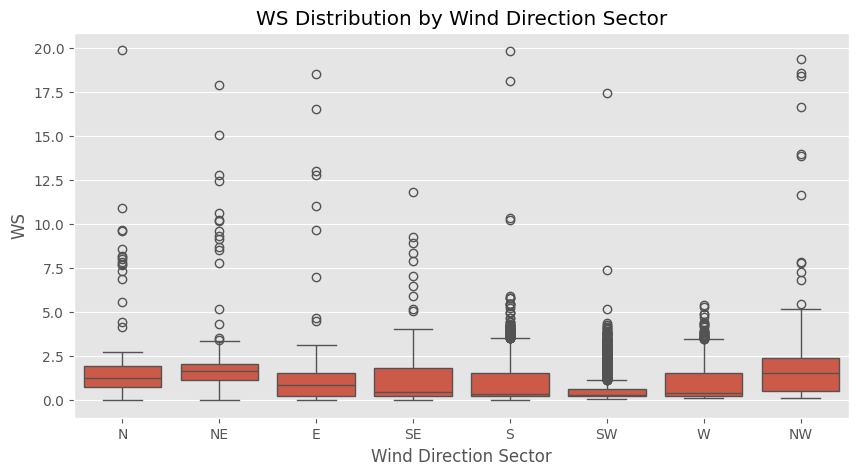

In [135]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=air,
    x="WD_sector",
    y="WS"
)

plt.title("WS Distribution by Wind Direction Sector")
plt.xlabel("Wind Direction Sector")
plt.ylabel("WS")

plt.show()

Does the Harmattan season have a measurable influence on the observed air quality and meteorological variables in the dataset?

- H₀ (Null Hypothesis): There is no significant difference in PM₂.₅, PM₁₀, and meteorological conditions between the Harmattan and non-Harmattan periods.

- H₁ (Alternative Hypothesis): The Harmattan period is associated with significantly different PM₂.₅, PM₁₀, and meteorological conditions

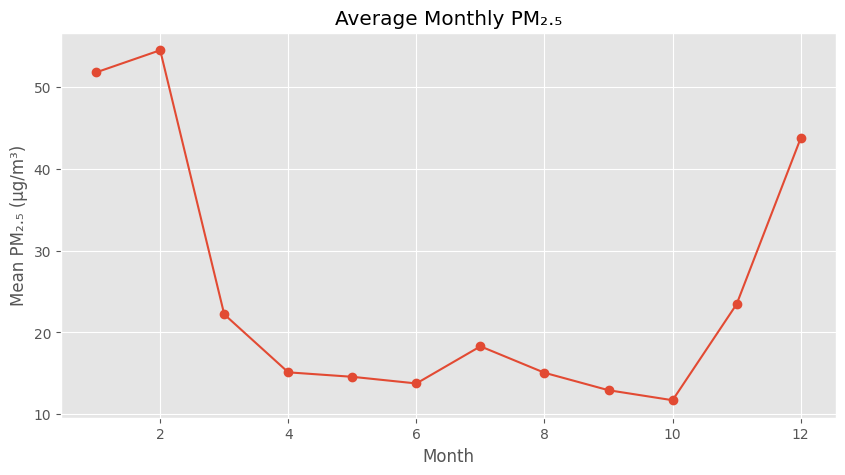

In [136]:
monthly_pm25 = (
    air.groupby(air["date"].dt.month)["PM2.5"]
       .mean()
)

plt.figure(figsize=(10,5))

monthly_pm25.plot(marker='o')

plt.title("Average Monthly PM₂.₅")
plt.xlabel("Month")
plt.ylabel("Mean PM₂.₅ (µg/m³)")

plt.grid(True)

plt.show()

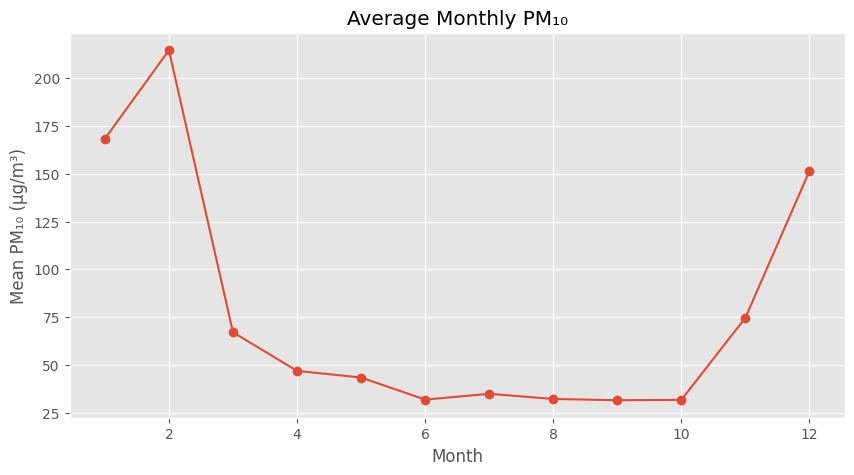

In [137]:
monthly_pm10 = (
    air.groupby(air["date"].dt.month)["PM10"]
       .mean()
)

plt.figure(figsize=(10,5))

monthly_pm10.plot(marker='o')

plt.title("Average Monthly PM₁₀")
plt.xlabel("Month")
plt.ylabel("Mean PM₁₀ (µg/m³)")

plt.grid(True)

plt.show()

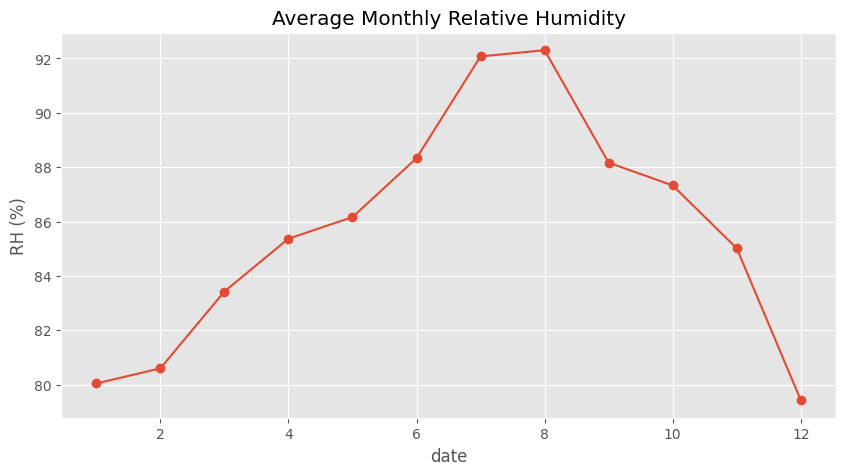

In [138]:
monthly_rh = (
    air.groupby(air["date"].dt.month)["RH"]
       .mean()
)

plt.figure(figsize=(10,5))

monthly_rh.plot(marker='o')

plt.title("Average Monthly Relative Humidity")

plt.ylabel("RH (%)")

plt.grid(True)

plt.show()

In [139]:
monthly_wd = (
    air.groupby(air["date"].dt.month)["WD"]
       .mean()
)

monthly_wd

,WD
date,
1,233.768354
2,232.116983
3,238.285453
4,239.493087
5,242.547662
6,245.518632
7,226.439156
8,220.708133
9,209.251373


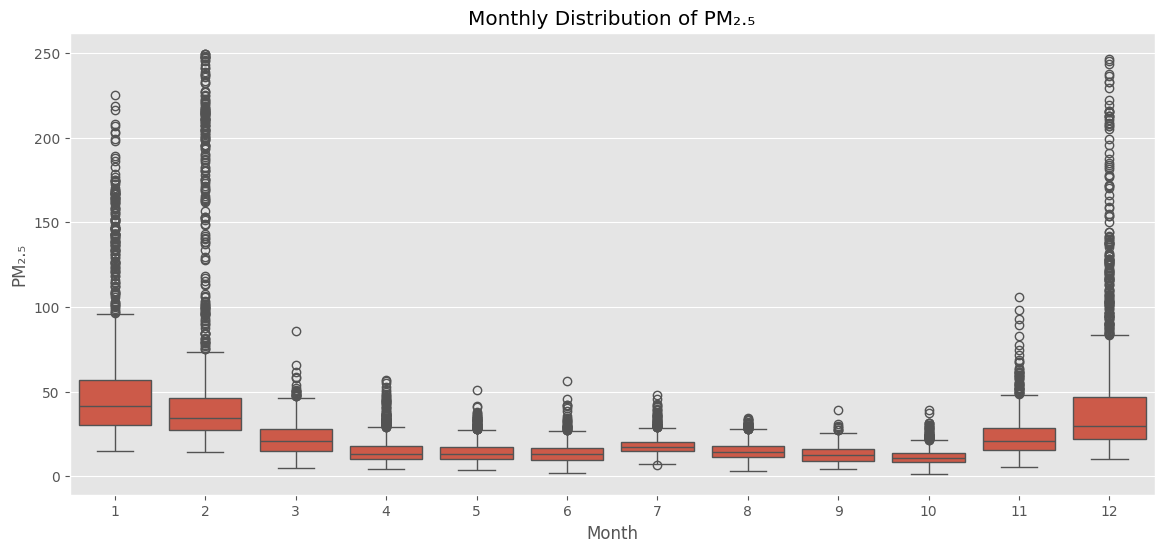

In [140]:
plt.figure(figsize=(14,6))

sns.boxplot(
    data=air,
    x=air["date"].dt.month,
    y="PM2.5"
)

plt.title("Monthly Distribution of PM₂.₅")

plt.xlabel("Month")

plt.ylabel("PM₂.₅")

plt.show()

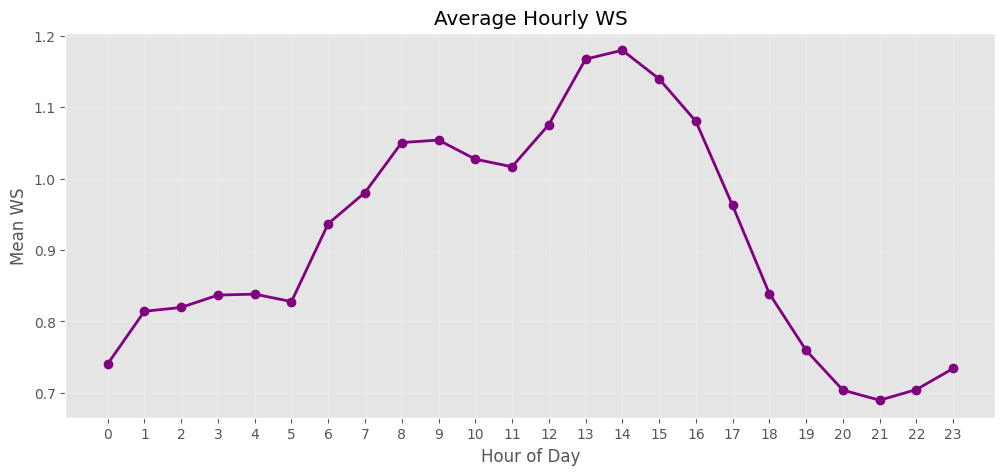

In [141]:
# Extract hour from datetime
air["Hour"] = air["date"].dt.hour

# Average hourly WS
hourly_ws = (
    air.groupby("Hour")["WS"]
       .mean()
)

plt.figure(figsize=(12,5))

plt.plot(
    hourly_ws.index,
    hourly_ws.values,
    marker="o",
    linewidth=2,
    color="purple"
)

plt.title("Average Hourly WS")
plt.xlabel("Hour of Day")
plt.ylabel("Mean WS")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()

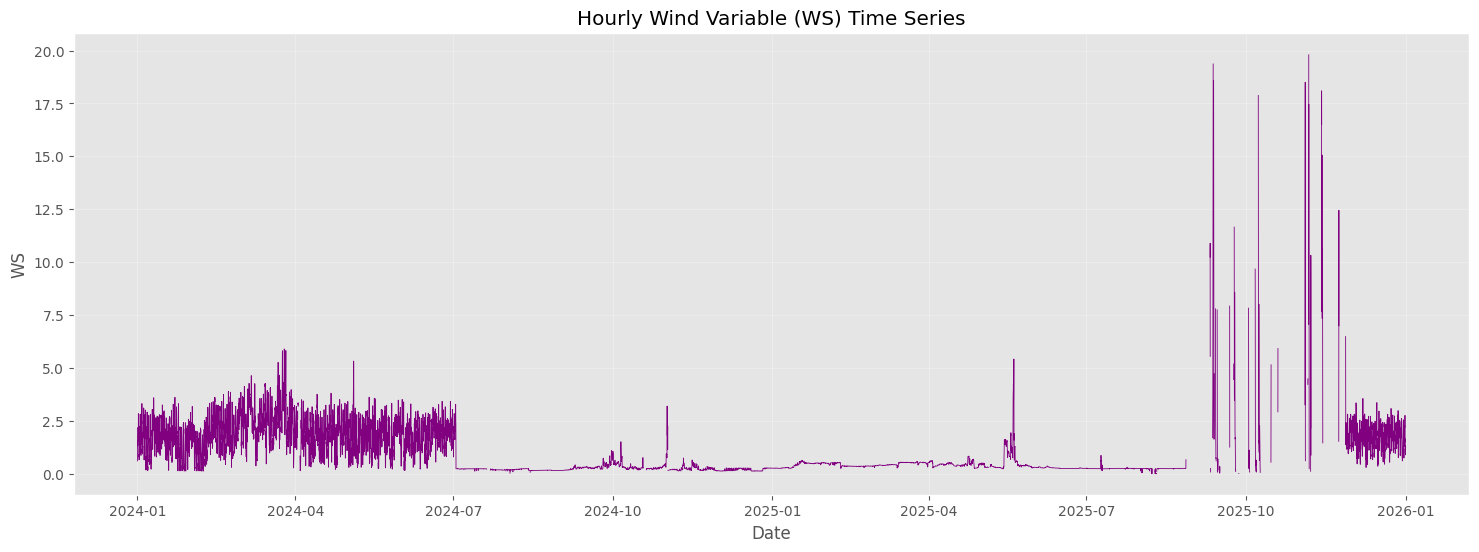

In [142]:
plt.figure(figsize=(18,6))

plt.plot(
    air["date"],
    air["WS"],
    color="purple",
    linewidth=0.6
)

plt.title("Hourly Wind Variable (WS) Time Series")
plt.xlabel("Date")
plt.ylabel("WS")

plt.grid(alpha=0.3)

plt.show()

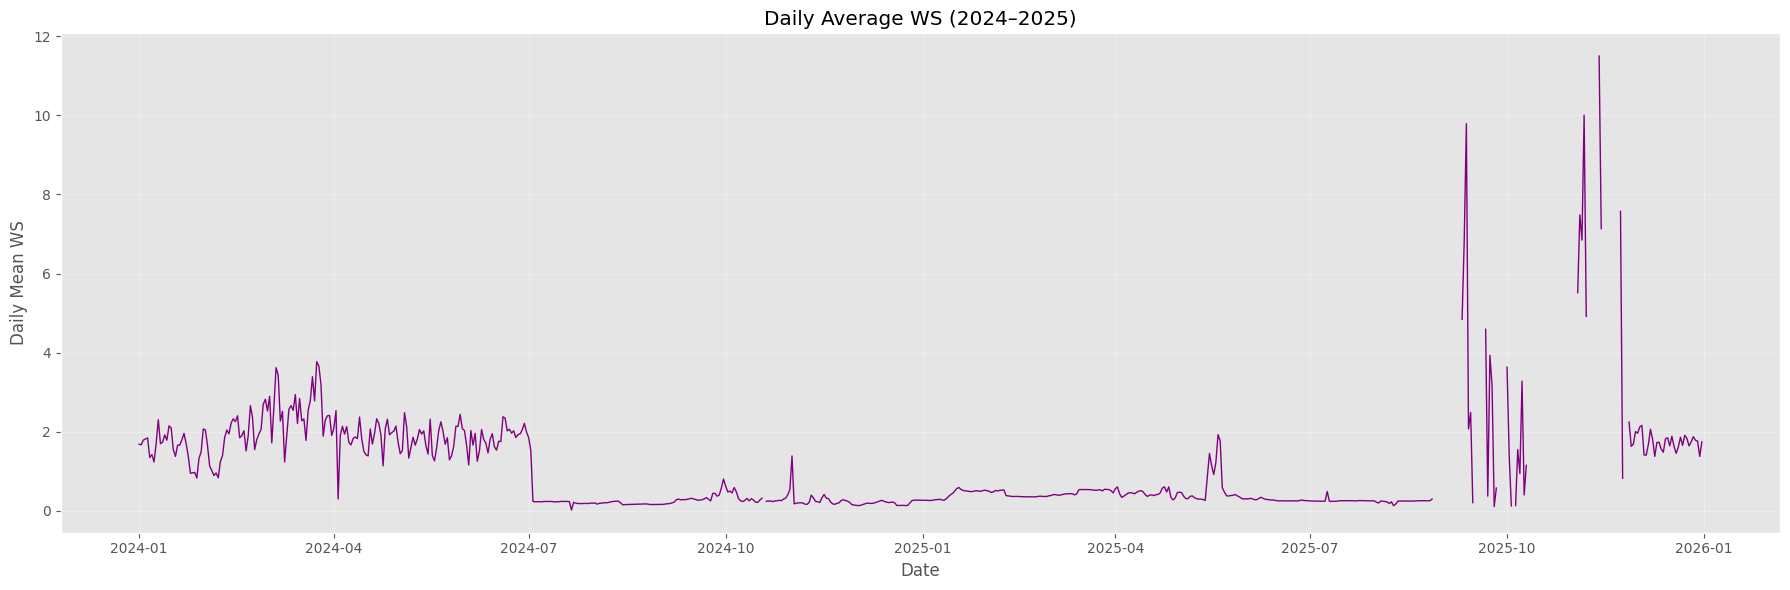

In [143]:
# Daily average WS
daily_ws = (
    air.set_index("date")["WS"]
       .resample("D")
       .mean()
)

plt.figure(figsize=(18,6))

plt.plot(
    daily_ws.index,
    daily_ws.values,
    color="purple",
    linewidth=1
)

plt.title("Daily Average WS (2024–2025)")
plt.xlabel("Date")
plt.ylabel("Daily Mean WS")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

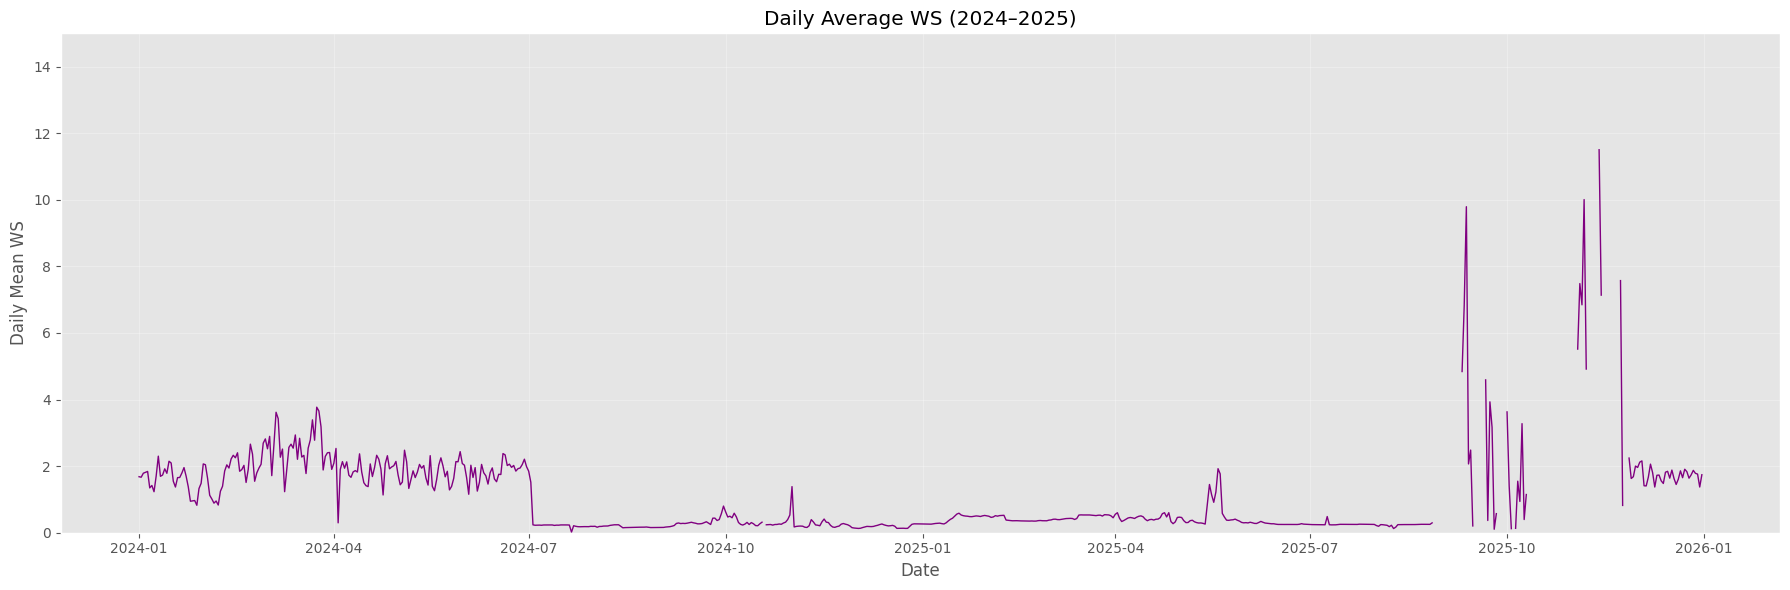

In [144]:
# Daily average WS
daily_ws = (
    air.set_index("date")["WS"]
       .resample("D")
       .mean()
)

plt.figure(figsize=(18,6))

plt.plot(
    daily_ws.index,
    daily_ws.values,
    color="purple",
    linewidth=1
)

plt.title("Daily Average WS (2024–2025)")
plt.xlabel("Date")
plt.ylabel("Daily Mean WS")

# Set y-axis limits
plt.ylim(0, 15)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

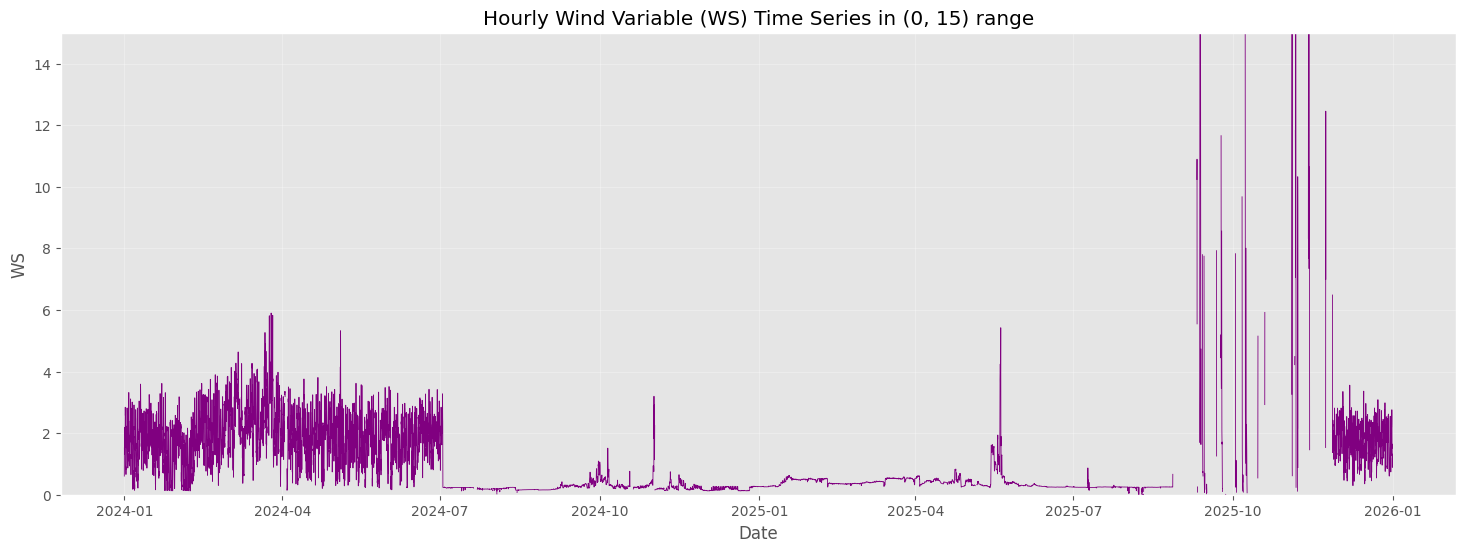

In [145]:
plt.figure(figsize=(18,6))

plt.plot(
    air["date"],
    air["WS"],
    color="purple",
    linewidth=0.6
)

plt.title("Hourly Wind Variable (WS) Time Series in (0, 15) range")
plt.xlabel("Date")
plt.ylabel("WS")

# Set y-axis limits
plt.ylim(0, 15)

plt.grid(alpha=0.3)

plt.show()

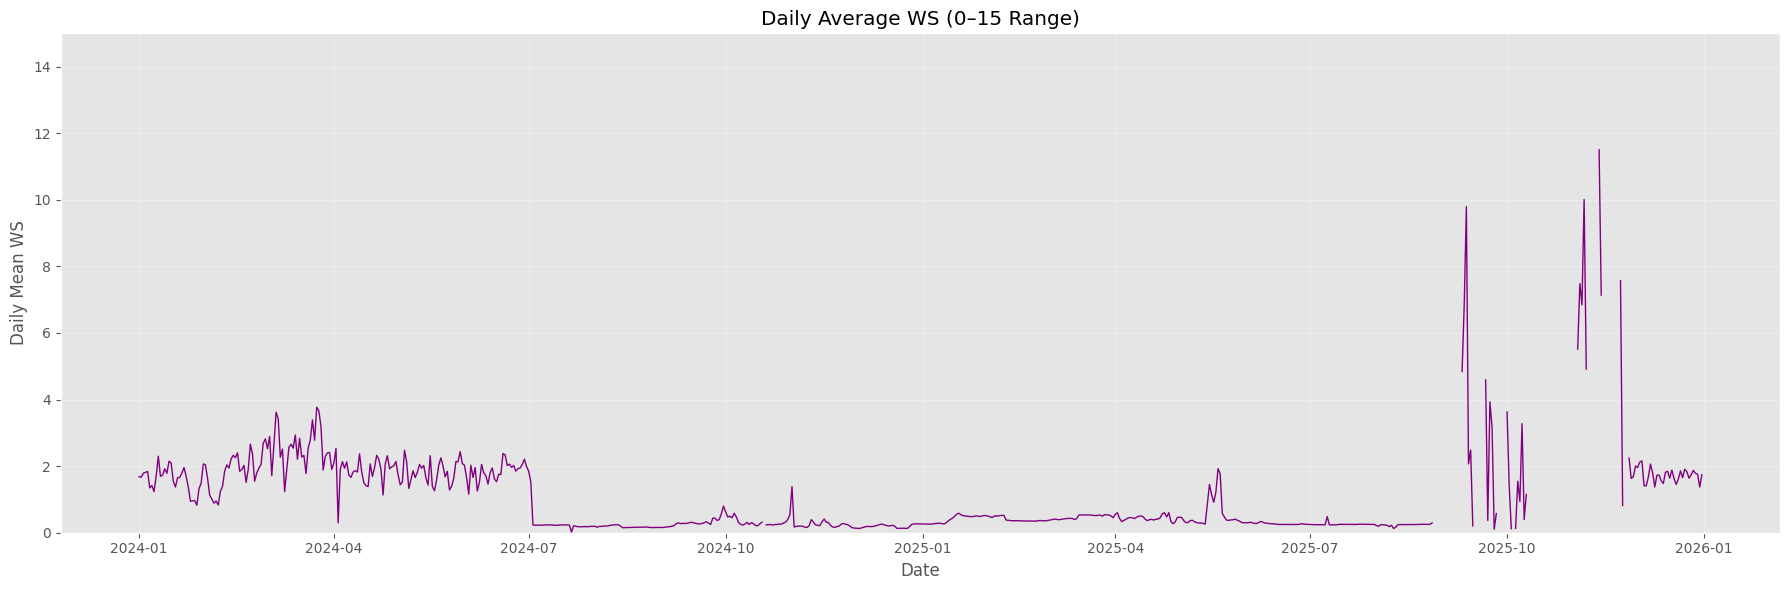

In [146]:
daily_ws = (
    air.set_index("date")["WS"]
       .resample("D")
       .mean()
)

# Keep only values between 0 and 15 for visualization
daily_ws_plot = daily_ws.where((daily_ws >= 0) & (daily_ws <= 15))

plt.figure(figsize=(18,6))

plt.plot(
    daily_ws_plot.index,
    daily_ws_plot.values,
    color="purple",
    linewidth=1
)

plt.title("Daily Average WS (0–15 Range)")
plt.xlabel("Date")
plt.ylabel("Daily Mean WS")

plt.ylim(0, 15)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [147]:
air.isnull().sum()

,0
date,0
PM10,537
PM2.5,556
RH,9217
Temp,106
WD,159
WS,2281
WD_sector,159
Hour,0


In [148]:
air["RH"].describe()

,RH
count,8327.000000
mean,85.093120
std,12.139580
min,25.850500
25%,76.711917
50%,87.183333
75%,95.620465
max,99.900000


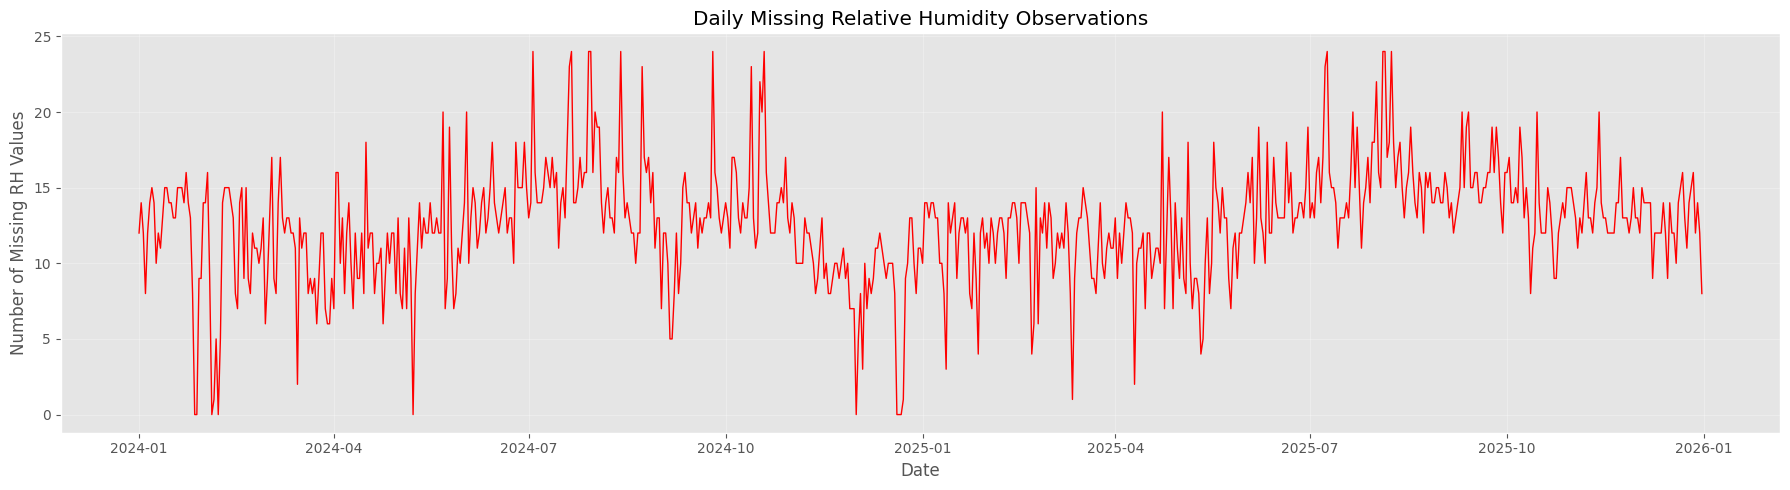

In [149]:
# Daily missing RH values
rh_missing_daily = (
    air["RH"]
    .isna()
    .groupby(air["date"].dt.date)
    .sum()
)

plt.figure(figsize=(18,5))

plt.plot(
    rh_missing_daily.index,
    rh_missing_daily.values,
    color="red",
    linewidth=1
)

plt.title("Daily Missing Relative Humidity Observations")
plt.xlabel("Date")
plt.ylabel("Number of Missing RH Values")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [150]:
air.loc[
    air["RH"].isna(),
    ["date", "RH", "Temp", "WD", "WS"]
].head(20)

,date,RH,Temp,WD,WS
0,2024-01-01 00:00:00,NaN,28.618305,260.566102,0.604881
1,2024-01-01 01:00:00,NaN,28.438167,279.908333,1.534783
2,2024-01-01 02:00:00,NaN,27.912167,285.158333,1.327000
3,2024-01-01 03:00:00,NaN,27.583500,289.420000,1.447833
4,2024-01-01 04:00:00,NaN,27.357000,286.768333,1.326083
5,2024-01-01 05:00:00,NaN,27.178500,284.533333,1.469467
6,2024-01-01 06:00:00,NaN,27.074000,284.688333,1.629383
7,2024-01-01 07:00:00,NaN,27.757000,287.320000,2.029117
20,2024-01-01 20:00:00,NaN,29.297500,205.241667,0.819867
21,2024-01-01 21:00:00,NaN,29.264333,223.313333,0.905550


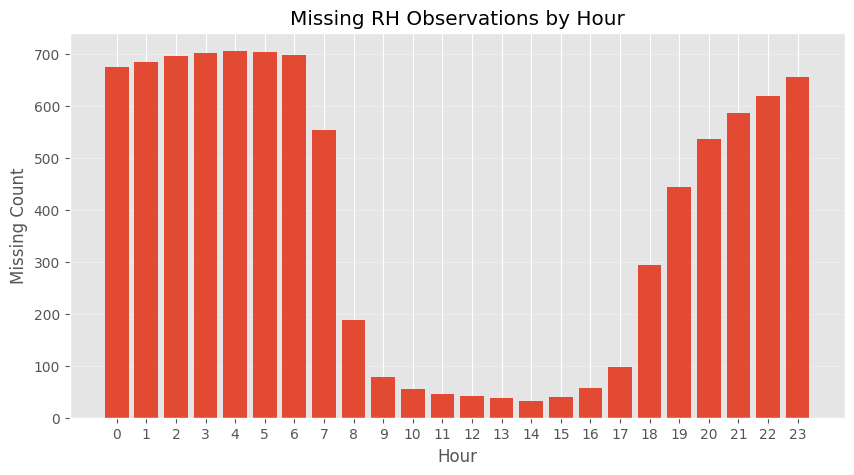

In [151]:
rh_hourly_missing = (
    air["RH"]
    .isna()
    .groupby(air["Hour"])
    .sum()
)

plt.figure(figsize=(10,5))

plt.bar(
    rh_hourly_missing.index,
    rh_hourly_missing.values
)

plt.title("Missing RH Observations by Hour")
plt.xlabel("Hour")
plt.ylabel("Missing Count")

plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.show()

In [152]:
rh_missing = air["RH"].isna()

# Identify consecutive missing groups
groups = (rh_missing != rh_missing.shift()).cumsum()

gap_lengths = (
    rh_missing.groupby(groups)
    .sum()
)

# Keep only actual missing gaps
gap_lengths = gap_lengths[gap_lengths > 0]

gap_lengths.describe()

,RH
count,806.000000
mean,11.435484
std,6.050116
min,1.000000
25%,8.000000
50%,12.000000
75%,14.000000
max,65.000000


In [153]:
gap_lengths.sort_values(ascending=False).head(20)

,RH
RH,
1289,65
493,63
1237,46
473,46
681,46
1293,42
431,40
527,40
631,38
